[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BASE-Laboratory/OpenImpala/blob/master/tutorials/04_multiphase_transport.ipynb)

# Multi-Phase Transport in Composite Media

Composite porous materials—such as lithium-ion battery cathodes (liquid electrolyte pore + nanoporous carbon-binder domain + active oxide), solid-state composite electrolytes, and partially saturated rocks—contain multiple phases with distinct finite transport coefficients $D_p \ge 0$. OpenImpala solves the variable-coefficient conservation law

$$-\nabla \cdot \bigl(D(\mathbf{x})\,\nabla \phi\bigr) = 0, \qquad D_{i+1/2} = \frac{2 D_i D_j}{D_i + D_j},$$

using harmonic-mean face conductances across phase interfaces so normal flux continuity is satisfied exactly on the voxel grid.

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q openimpala matplotlib scipy

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
import openimpala as oi

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## Verification Against Exact Wiener (Voigt and Reuss) Bounds

For an equal-volume two-phase laminate with phase diffusivities $D_1 = 1$ and $D_2 = \kappa \in (0, 1]$, transport parallel to the layers follows the arithmetic Voigt bound and transport normal to the layers follows the harmonic Reuss bound:

$$D_{\parallel}(\kappa) = \frac{1 + \kappa}{2}, \qquad D_{\perp}(\kappa) = \frac{2\kappa}{1 + \kappa}.$$

In [3]:
slab = np.zeros((16, 16, 16), dtype=np.int32)
slab[:, :, :8] = 1  # interface normal to X (axis 2)

ratios = np.logspace(-3, 0, 7)
d_voigt_num, d_reuss_num = [], []

for kappa in ratios:
    coeffs = {0: float(kappa), 1: 1.0}
    d_voigt_num.append(oi.tortuosity(slab, direction="z", phase_diffusivities=coeffs).effective_diffusivity)
    d_reuss_num.append(oi.tortuosity(slab, direction="x", phase_diffusivities=coeffs).effective_diffusivity)

d_voigt_exact = 0.5 * (1.0 + ratios)
d_reuss_exact = 2.0 * ratios / (1.0 + ratios)
assert np.allclose(d_voigt_num, d_voigt_exact, rtol=1e-5)
assert np.allclose(d_reuss_num, d_reuss_exact, rtol=1e-5)

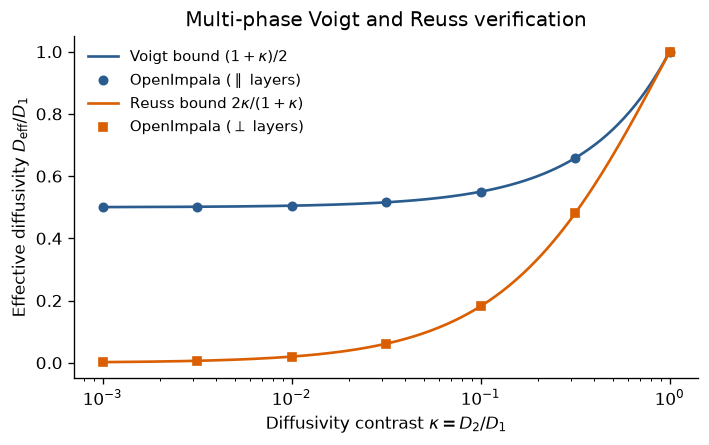

In [4]:
k_fine = np.logspace(-3, 0, 200)
fig, ax = plt.subplots(figsize=(5.8, 3.6), constrained_layout=True)

ax.semilogx(k_fine, 0.5 * (1.0 + k_fine), color="#2b5c8f", lw=1.6, label=r"Voigt bound $(1 + \kappa)/2$")
ax.semilogx(ratios, d_voigt_num, "o", color="#2b5c8f", ms=5, label=r"OpenImpala ($\parallel$ layers)")
ax.semilogx(k_fine, 2.0 * k_fine / (1.0 + k_fine), color="#d95f02", lw=1.6, label=r"Reuss bound $2\kappa/(1 + \kappa)$")
ax.semilogx(ratios, d_reuss_num, "s", color="#d95f02", ms=5, label=r"OpenImpala ($\perp$ layers)")

ax.set_xlabel(r"Diffusivity contrast $\kappa = D_2 / D_1$")
ax.set_ylabel(r"Effective diffusivity $D_{\mathrm{eff}} / D_1$")
ax.set_title("Multi-phase Voigt and Reuss verification")
ax.legend(frameon=False, fontsize=9)
plt.show()

## Bridging Across Pinched Pore Throats in a 3-Phase Electrode

In composite electrodes, a nanoporous binder or interphase layer (`phase=2`) coats the insulating solid matrix (`phase=0`) and narrows or closes off the primary macropore network (`phase=1`). We construct such a 3-phase volume from `two_phase_cubic()` by assigning a 1-voxel interfacial shell of the pore space to `phase=2`:

In [5]:
base = oi.datasets.two_phase_cubic()
pore = base == 1
macropore = ndimage.binary_erosion(pore, iterations=1)

composite = np.zeros_like(base)       # phase 0: insulating active particles (D = 0)
composite[pore & ~macropore] = 2      # phase 2: nanoporous binder shell
composite[macropore] = 1              # phase 1: open electrolyte macropores

for pid, label in ((0, "Insulating solid"), (1, "Open macropore"), (2, "Nanoporous binder")):
    print(f"Phase {pid} ({label:18s}): {np.mean(composite == pid):.3f}")

oi.percolation_check(composite, phase=1, direction="z")

Phase 0 (Insulating solid  ): 0.601
Phase 1 (Open macropore    ): 0.105
Phase 2 (Nanoporous binder ): 0.294


Metric,Value
Direction,Z
Percolates,No
Active VF,0.000000


Because the eroded macropores (`phase=1`) no longer percolate on their own, a single-phase pore solve would predict zero macroscopic transport. Including physical SI ionic diffusivities (`phase 1`: $D_{\text{pore}} = 3.0 \times 10^{-10}\;\mathrm{m^2\,s^{-1}}$, `phase 2`: $D_{\text{binder}} = 3.0 \times 10^{-11}\;\mathrm{m^2\,s^{-1}}$, `phase 0`: $0$) restores conduction via series bridges across the binder necks:

In [6]:
d_pore = 3.0e-10  # m^2/s
res_comp = oi.tortuosity(
    composite,
    direction="z",
    voxel_size=0.5e-6,
    phase_diffusivities={0: 0.0, 1: d_pore, 2: 0.1 * d_pore},
    return_field=True,
)
res_comp

Metric,Value
Tortuosity,59966706832.893494
Effective diffusivity,6.620902e-12
Solver status,converged
Iterations,871
Residual norm,9.83e-10
Flux in,-2.118689e-16
Flux out,-2.118689e-16
Active VF,0.397034


Sweeping $D_{\text{binder}} / D_{\text{pore}} \in [0.01, 1]$ across the typical nanoporous binder range quantifies the transition from binder-limited choke points ($D_{\text{eff}} \propto D_{\text{binder}}$) to open two-phase conduction:

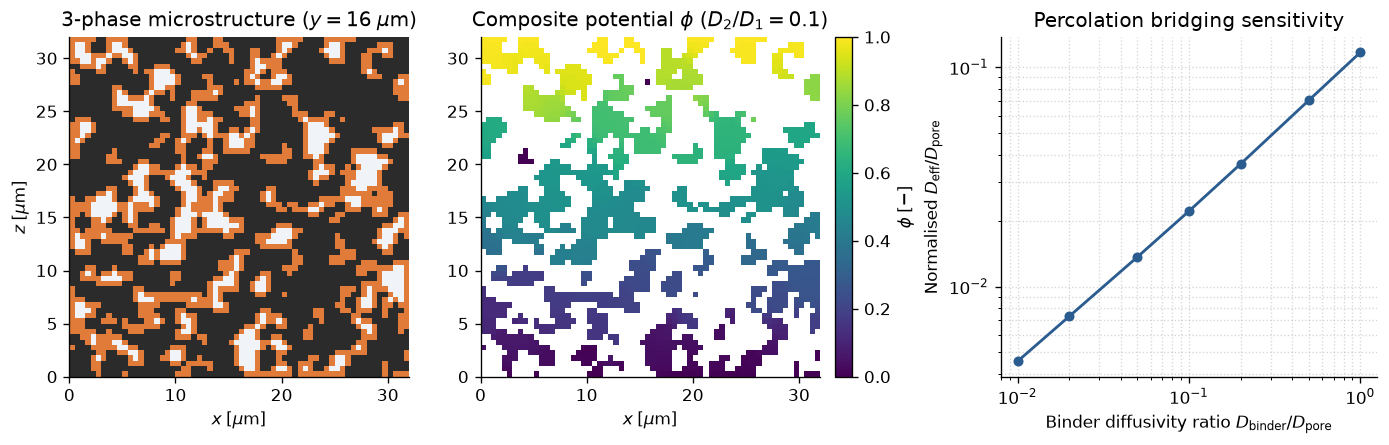

In [7]:
contrast = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0])
deff_ratio = [
    oi.tortuosity(
        composite,
        direction="z",
        phase_diffusivities={0: 0.0, 1: 1.0, 2: float(c)},
    ).effective_diffusivity
    for c in contrast
]

mid_y = composite.shape[1] // 2
extent_um = [0.0, composite.shape[2] * 0.5, 0.0, composite.shape[0] * 0.5]
phi_masked = np.where(composite > 0, res_comp.solution_field, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), constrained_layout=True)

cmap_phases = plt.matplotlib.colors.ListedColormap(["#2b2b2b", "#f0f4f8", "#e07b39"])
axes[0].imshow(composite[:, mid_y, :], origin="lower", extent=extent_um, cmap=cmap_phases, vmin=0, vmax=2)
axes[0].set_title(r"3-phase microstructure ($y = 16\;\mu$m)")
axes[0].set_xlabel(r"$x\;[\mu\mathrm{m}]$")
axes[0].set_ylabel(r"$z\;[\mu\mathrm{m}]$")

im_phi = axes[1].imshow(phi_masked[:, mid_y, :], origin="lower", extent=extent_um, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title(r"Composite potential $\phi$ ($D_2 / D_1 = 0.1$)")
axes[1].set_xlabel(r"$x\;[\mu\mathrm{m}]$")
fig.colorbar(im_phi, ax=axes[1], fraction=0.046, pad=0.04, label=r"$\phi\;[-]$")

axes[2].loglog(contrast, deff_ratio, "o-", color="#2b5c8f", lw=1.7, ms=5)
axes[2].set_xlabel(r"Binder diffusivity ratio $D_{\mathrm{binder}} / D_{\mathrm{pore}}$")
axes[2].set_ylabel(r"Normalised $D_{\mathrm{eff}} / D_{\mathrm{pore}}$")
axes[2].set_title("Percolation bridging sensitivity")
axes[2].grid(True, which="both", ls=":", alpha=0.5)

plt.show()

## References

1. Z. Hashin and S. Shtrikman, *A variational approach to the theory of the effective magnetic permeability of multiphase materials*, J. Appl. Phys. **33**(10), 3125–3131 (1962).
2. J. Landesfeind, J. Hattendorff, A. Ehrl, W. A. Wall, and H. A. Gasteiger, *Tortuosity determination of battery electrodes and separators by impedance spectroscopy*, J. Electrochem. Soc. **163**(7), A1373–A1387 (2016).